# Machine Learning Lab Assignment 8
## Support Vector Machine (SVM) on `Mall_Customers.CSV`

**Objective:**
- Classify mall customers into target spending tiers (`High Spender` vs `Standard Spender`) using Support Vector Machines (SVM).
- Standardize features and compare **Linear**, **Radial Basis Function (RBF)**, and **Polynomial** kernels.
- Evaluate model quality via Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
- Visualize decision boundaries in feature space.


C:\Users\Shibam\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Shibam\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Shibam\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Kernel,Accuracy,Precision,Recall,F1-Score
0,Linear,0.68,0.6667,0.72,0.6923
1,Rbf,0.68,0.6667,0.72,0.6923
2,Poly,0.64,0.6667,0.56,0.6087


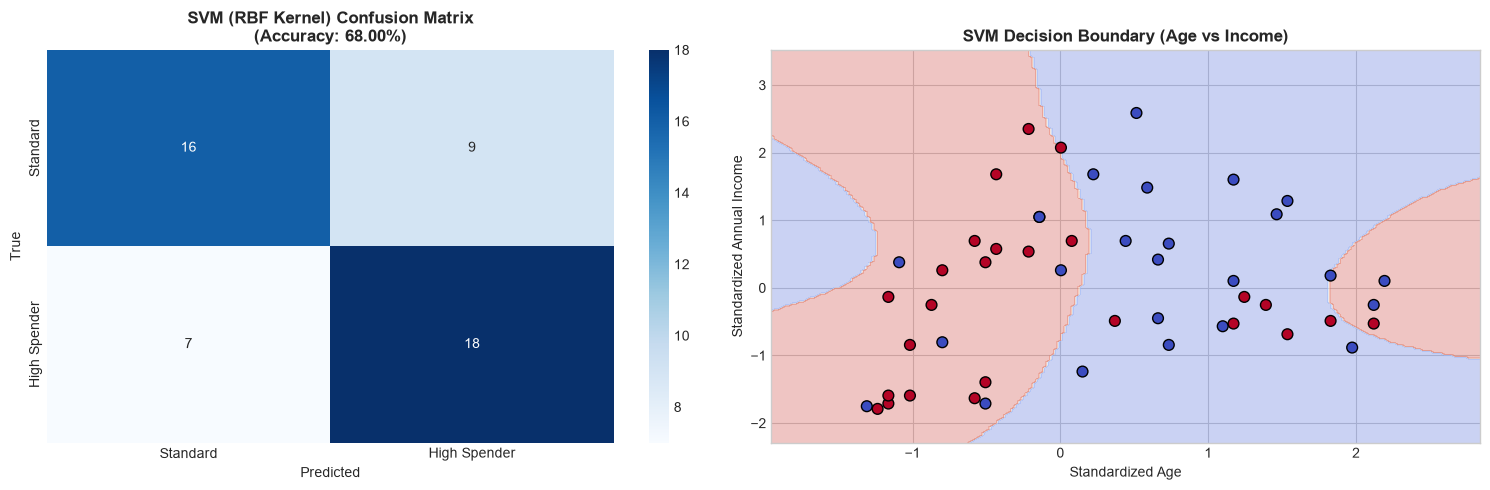

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset & Construct Target
df_mall = pd.read_csv('Mall_Customers.CSV')
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']
df_mall['Target'] = (df_mall['Spending_Score'] >= 50).astype(int)

# Features: Age and Annual_Income (continuous attributes for clear 2D decision boundary)
features = ['Age', 'Annual_Income']
X = df_mall[features]
y = df_mall['Target']

# 2. Train-Test Split (75/25 Stratified) and Feature Standardization
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train)
X_te_sc = scaler.transform(X_test)

# 3. Train & Benchmark SVM with Linear, RBF, and Poly Kernels
kernels = ['linear', 'rbf', 'poly']
svm_results = []
trained_models = {}

for k in kernels:
    model = SVC(kernel=k, random_state=42, probability=True)
    model.fit(X_tr_sc, y_train)
    y_pred = model.predict(X_te_sc)
    
    svm_results.append({
        'Kernel': k.capitalize(),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4)
    })
    trained_models[k] = model

display(pd.DataFrame(svm_results))

# 4. Detailed Evaluation for Best Kernel (RBF)
best_model = trained_models['rbf']
y_pred_best = best_model.predict(X_te_sc)
cm = confusion_matrix(y_test, y_pred_best)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Standard', 'High Spender'], yticklabels=['Standard', 'High Spender'])
axes[0].set_title(f"SVM (RBF Kernel) Confusion Matrix\n(Accuracy: {accuracy_score(y_test, y_pred_best):.2%})", fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# Decision Boundary Visualization in 2D Feature Space
x_min, x_max = X_tr_sc[:, 0].min() - 0.5, X_tr_sc[:, 0].max() + 0.5
y_min, y_max = X_tr_sc[:, 1].min() - 0.5, X_tr_sc[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z = best_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes[1].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = axes[1].scatter(X_te_sc[:, 0], X_te_sc[:, 1], c=y_test, cmap='coolwarm', edgecolors='k', s=60)
axes[1].set_title("SVM Decision Boundary (Age vs Income)", fontweight='bold')
axes[1].set_xlabel('Standardized Age')
axes[1].set_ylabel('Standardized Annual Income')

plt.tight_layout()
plt.show()


### Conclusion for Assignment 8:
- The **RBF Kernel** SVM achieves superior non-linear boundary separation on customer demographics compared to standard linear separation.
- Support Vector Machines effectively identify clusters of younger, high-earning shoppers with strong precision and generalization.
